In [1]:
import spatialdata as spd
import spatialdata_plot as splt
import spatialdata_io as so
import geosketch as sketch
import numpy as np
import pandas as pd
import scanpy as sc
import scanpy.external as sce

import json
import gc
import geopandas as gpd
from spatialdata.models import Image2DModel, TableModel, ShapesModel
import matplotlib.pyplot as plt

from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from PIL import Image
from spatialdata.transformations import Identity, Scale
from shapely.geometry import Polygon

/rwthfs/rz/cluster/home/fp015734/micromamba/envs/spatial_data/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/rwthfs/rz/cluster/home/fp015734/micromamba/envs/spatial_data/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/rwthfs/rz/cluster/home/fp015734/micromamba/envs/spatial_data/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is depreca

### Define functions to read in the spaceranger output

In [2]:
def create_zarr(count_matrix_path,
                image_path,
                scale_factors_path,
                geojson_path,
                sample_name
):
    print(sample_name)

    # Load and Prepare Raw Data
    # Define file paths
    COUNT_MATRIX_PATH = count_matrix_path
    IMAGE_PATH = image_path
    SCALE_FACTORS_PATH = scale_factors_path
    GEOJSON_PATH = geojson_path

    # Load AnnData
    adata = sc.read_10x_h5(COUNT_MATRIX_PATH)
    adata.var_names_make_unique()
    adata.obs['sample'] = sample_name
    adata.obs.index = sample_name +"_" + adata.obs.index.astype(str)

    # Load and preprocess image data
    image_data = np.array(Image.open(IMAGE_PATH))
    if image_data.ndim == 2:
        image_data = image_data[np.newaxis, :, :] # Add channel dimension for grayscale
    elif image_data.ndim == 3:
        image_data = np.transpose(image_data, (2, 0, 1)) # (H, W, C) -> (C, H, W) for spatialdata

    # Load scale factors
    with open(SCALE_FACTORS_PATH, 'r') as f:
        scale_data = json.load(f)

    # Load GeoJSON data
    with open(GEOJSON_PATH, 'r') as f:
        geojson_data = json.load(f)

    # Define coordinate systems:
    # `downscale_to_hires`: The coordinate system where shapes are located, scaled relative to the hires resolution.

    hires_scale = scale_data['tissue_hires_scalef']

    # Transformation for shapes (from pixel to downscale_to_hires)
    shapes_transformations = {
       "downscale_to_hires": Scale(np.array([hires_scale, hires_scale]), axes=("x", "y")) # if the high-resolution microscope image is being used and Identity() transform would be performed.
    }

    # Transformation for the 'hires_tissue_image' (it's already in the 'downscale_to_hires' space visually)
    image_transformations = {
        "downscale_to_hires": Identity()
    }

    # Process Cell Segmentation (GeoJSON) and Integrate with AnnData

    # Create a mapping from adata.obs.index to geojson features
    geojson_features_map = {
        f"{sample_name}_cellid_{feature['properties']['cell_id']:09d}-1": feature
        for feature in geojson_data['features']
    }

    # Prepare data for GeoDataFrame and update adata.obs
    geometries = []
    cell_ids_ordered = []

    for obs_index_str in adata.obs.index:
        feature = geojson_features_map.get(obs_index_str)
        if feature:
            # Create shapely Polygon from coordinates
            polygon_coords = np.array(feature['geometry']['coordinates'][0])
            geometries.append(Polygon(polygon_coords))
            cell_ids_ordered.append(obs_index_str)
        else:
            geometries.append(None) # Or a suitable placeholder
            cell_ids_ordered.append(obs_index_str)

    # Remove None entries if any (or handle them upstream)
    valid_indices = [i for i, geom in enumerate(geometries) if geom is not None]
    geometries = [geometries[i] for i in valid_indices]
    cell_ids_ordered = [cell_ids_ordered[i] for i in valid_indices]


    # Create GeoDataFrame for shapes
    shapes_gdf = gpd.GeoDataFrame({
        'cell_id': cell_ids_ordered,
        'geometry': geometries
    }, index=cell_ids_ordered)
    # Update adata.obs with cluster information and spatial identifiers
    adata.obs['cell_id'] = adata.obs.index
    adata.obs['region'] = sample_name + '_cell_boundaries'
    adata.obs['region'] = adata.obs['region'].astype('category')
    adata = adata[shapes_gdf.index].copy() # Filter adata to match shapes_gdf

    # Define names for SpatialData elements
    IMAGE_KEY =  sample_name + '_hires_tissue_image'
    TABLE_KEY =  'segmentation_counts'
    SHAPES_KEY = sample_name + '_cell_boundaries'

    # Create SpatialData elements directly
    sdata = spd.SpatialData(
        images={
            IMAGE_KEY: Image2DModel.parse(image_data, transformations=image_transformations)
        },
        tables={
            TABLE_KEY: TableModel.parse(
                adata,
                region=SHAPES_KEY, # Link table to shapes element
                region_key='region', # Column in adata.obs indicating region name
                instance_key='cell_id' # Column in adata.obs with instance IDs (cell_id)
            )
        },
        shapes={
            SHAPES_KEY: ShapesModel.parse(shapes_gdf, transformations=shapes_transformations)
        }
    )

    sdata.write(sample_name, overwrite=True)
    del sdata
    gc.collect()

In [1]:
def crop0(x,crs,bbox):
    return spd.bounding_box_query(
        x,
        min_coordinate=[bbox['x'][0], bbox['y'][0]],
        max_coordinate=[bbox['x'][1], bbox['y'][1]],
        axes=("x", "y"),
        target_coordinate_system=crs,
    )

### Read in the data and create zarr files

In [4]:
import os

os.chdir('/hpcwork/p0020567/data/dbit-seq/Visium_HD/analysis/zarr')
# Create and save Zarr files for the cell segmentation outputs.
samples = {
    "63511":["/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_63511/outs/segmented_outputs/filtered_feature_cell_matrix.h5",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_63511/outs/segmented_outputs/spatial/tissue_hires_image.png",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_63511/outs/segmented_outputs/spatial/scalefactors_json.json",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_63511/outs/segmented_outputs/cell_segmentations.geojson",
                      "63511"],
    "76504":["/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_76504/outs/segmented_outputs/filtered_feature_cell_matrix.h5",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_76504/outs/segmented_outputs/spatial/tissue_hires_image.png",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_76504/outs/segmented_outputs/spatial/scalefactors_json.json",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_76504/outs/segmented_outputs/cell_segmentations.geojson",
                      "76504"],
    "62791":["/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD3_62791/outs/segmented_outputs/filtered_feature_cell_matrix.h5",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD3_62791/outs/segmented_outputs/spatial/tissue_hires_image.png",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD3_62791/outs/segmented_outputs/spatial/scalefactors_json.json",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD3_62791/outs/segmented_outputs/cell_segmentations.geojson",
                      "62791"],
    "63212":["/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD3_63212/outs/segmented_outputs/filtered_feature_cell_matrix.h5",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD3_63212/outs/segmented_outputs/spatial/tissue_hires_image.png",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD3_63212/outs/segmented_outputs/spatial/scalefactors_json.json",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD3_63212/outs/segmented_outputs/cell_segmentations.geojson",
                      "63212"],
    "71116":["/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD3_71116/outs/segmented_outputs/filtered_feature_cell_matrix.h5",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD3_71116/outs/segmented_outputs/spatial/tissue_hires_image.png",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD3_71116/outs/segmented_outputs/spatial/scalefactors_json.json",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD3_71116/outs/segmented_outputs/cell_segmentations.geojson",
                      "71116"],
    "72330":["/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD3_72330/outs/segmented_outputs/filtered_feature_cell_matrix.h5",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD3_72330/outs/segmented_outputs/spatial/tissue_hires_image.png",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD3_72330/outs/segmented_outputs/spatial/scalefactors_json.json",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD3_72330/outs/segmented_outputs/cell_segmentations.geojson",
                      "72330"],
    "72351":["/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_72351_HE/outs/segmented_outputs/filtered_feature_cell_matrix.h5",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_72351_HE/outs/segmented_outputs/spatial/tissue_hires_image.png",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_72351_HE/outs/segmented_outputs/spatial/scalefactors_json.json",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_72351_HE/outs/segmented_outputs/cell_segmentations.geojson",
                      "72351"],
    "76504":["/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_76504/outs/segmented_outputs/filtered_feature_cell_matrix.h5",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_76504/outs/segmented_outputs/spatial/tissue_hires_image.png",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_76504/outs/segmented_outputs/spatial/scalefactors_json.json",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_76504/outs/segmented_outputs/cell_segmentations.geojson",
                      "76504"],
    "76992":["/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_76992_high/outs/segmented_outputs/filtered_feature_cell_matrix.h5",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_76992_high/outs/segmented_outputs/spatial/tissue_hires_image.png",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_76992_high/outs/segmented_outputs/spatial/scalefactors_json.json",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_76992_high/outs/segmented_outputs/cell_segmentations.geojson",
                      "76992"],
    "76997":["/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_76997_high/outs/segmented_outputs/filtered_feature_cell_matrix.h5",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_76997_high/outs/segmented_outputs/spatial/tissue_hires_image.png",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_76997_high/outs/segmented_outputs/spatial/scalefactors_json.json",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_76997_high/outs/segmented_outputs/cell_segmentations.geojson",
                      "76997"],
    "77423":["/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_77423/outs/segmented_outputs/filtered_feature_cell_matrix.h5",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_77423/outs/segmented_outputs/spatial/tissue_hires_image.png",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_77423/outs/segmented_outputs/spatial/scalefactors_json.json",
                      "/hpcwork/p0020567/data/dbit-seq/Visium_HD/spaceranger_output/Visium_HD_77423/outs/segmented_outputs/cell_segmentations.geojson",
                      "77423"]   
}
print("Saving zarr files")
for key, inputs in samples.items():
    create_zarr(count_matrix_path=inputs[0],
                image_path=inputs[1],
                scale_factors_path=inputs[2],
                geojson_path=inputs[3],
                sample_name=inputs[4])

del samples, inputs, key
gc.collect()

Saving zarr files
63511
INFO     no axes information specified in the object, setting `dims` to: ('c', 'y', 'x')                           
INFO     The Zarr backing store has been changed from None the new file path: 63511                                
76504
INFO     no axes information specified in the object, setting `dims` to: ('c', 'y', 'x')                           
INFO     The Zarr backing store has been changed from None the new file path: 76504                                
62791


/rwthfs/rz/cluster/home/fp015734/micromamba/envs/spatial_data/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/rwthfs/rz/cluster/home/fp015734/micromamba/envs/spatial_data/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


INFO     no axes information specified in the object, setting `dims` to: ('c', 'y', 'x')                           
INFO     The Zarr backing store has been changed from None the new file path: 62791                                
63212


/rwthfs/rz/cluster/home/fp015734/micromamba/envs/spatial_data/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/rwthfs/rz/cluster/home/fp015734/micromamba/envs/spatial_data/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


INFO     no axes information specified in the object, setting `dims` to: ('c', 'y', 'x')                           
INFO     The Zarr backing store has been changed from None the new file path: 63212                                
71116


/rwthfs/rz/cluster/home/fp015734/micromamba/envs/spatial_data/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/rwthfs/rz/cluster/home/fp015734/micromamba/envs/spatial_data/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


INFO     no axes information specified in the object, setting `dims` to: ('c', 'y', 'x')                           
INFO     The Zarr backing store has been changed from None the new file path: 71116                                
72330


/rwthfs/rz/cluster/home/fp015734/micromamba/envs/spatial_data/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/rwthfs/rz/cluster/home/fp015734/micromamba/envs/spatial_data/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


INFO     no axes information specified in the object, setting `dims` to: ('c', 'y', 'x')                           
INFO     The Zarr backing store has been changed from None the new file path: 72330                                
72351
INFO     no axes information specified in the object, setting `dims` to: ('c', 'y', 'x')                           
INFO     The Zarr backing store has been changed from None the new file path: 72351                                
76992
INFO     no axes information specified in the object, setting `dims` to: ('c', 'y', 'x')                           
INFO     The Zarr backing store has been changed from None the new file path: 76992                                
76997
INFO     no axes information specified in the object, setting `dims` to: ('c', 'y', 'x')                           
INFO     The Zarr backing store has been changed from None the new file path: 76997                                
77423
INFO     no axes information specified in the ob

0

In [5]:
# Loading the zarr files
visium_hd_zarr_paths = {
    "63511": "/hpcwork/p0020567/data/dbit-seq/Visium_HD/analysis/zarr/63511",
    "76504": "/hpcwork/p0020567/data/dbit-seq/Visium_HD/analysis/zarr/76504",
    "62791": "/hpcwork/p0020567/data/dbit-seq/Visium_HD/analysis/zarr/62791",
    "63212": "/hpcwork/p0020567/data/dbit-seq/Visium_HD/analysis/zarr/63212",
    "71116": "/hpcwork/p0020567/data/dbit-seq/Visium_HD/analysis/zarr/71116",
    "72330": "/hpcwork/p0020567/data/dbit-seq/Visium_HD/analysis/zarr/72330",
    "72351": "/hpcwork/p0020567/data/dbit-seq/Visium_HD/analysis/zarr/72351",
    "76992": "/hpcwork/p0020567/data/dbit-seq/Visium_HD/analysis/zarr/76992",
    "76997": "/hpcwork/p0020567/data/dbit-seq/Visium_HD/analysis/zarr/76997",
    "77423": "/hpcwork/p0020567/data/dbit-seq/Visium_HD/analysis/zarr/77423",
}


# Loading samples into a dictionary
sdatas = []
for key, path in visium_hd_zarr_paths.items():
    sdata = spd.read_zarr(path)

    for table in sdata.tables.values():
        table.var_names_make_unique()
        table.obs["sample"] = key

    sdatas.append(sdata)
    del sdata, table
    gc.collect()
# Concatenate
concatenated_sdata = spd.concatenate(sdatas, concatenate_tables=True)

concatenated_sdata.write("concatenated_sdata", overwrite=True)

del concatenated_sdata,sdatas,visium_hd_zarr_paths, key, path
gc.collect()

concatenated_sdata = spd.read_zarr("concatenated_sdata")

print("---------------------------------")
print(concatenated_sdata)

version mismatch: detected: RasterFormatV02, requested: FormatV04
/rwthfs/rz/cluster/home/fp015734/micromamba/envs/spatial_data/lib/python3.10/site-packages/zarr/creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
/rwthfs/rz/cluster/home/fp015734/micromamba/envs/spatial_data/lib/python3.10/site-packages/zarr/creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
/rwthfs/rz/cluster/home/fp015734/micromamba/envs/spatial_data/lib/python3.10/site-packages/zarr/creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
/rwthfs/rz/cluster/hom

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside concatenated_sdata). Please see the documentation of `is_self_contained()` to understand
         the implications of working with SpatialData objects that are not self-contained.                         
INFO     The Zarr backing store has been changed from None the new file path: concatenated_sdata                   


version mismatch: detected: RasterFormatV02, requested: FormatV04
/rwthfs/rz/cluster/home/fp015734/micromamba/envs/spatial_data/lib/python3.10/site-packages/zarr/creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04


---------------------------------
SpatialData object, with associated Zarr store: /rwthfs/rz/cluster/hpcwork/p0020567/data/dbit-seq/Visium_HD/analysis/zarr/concatenated_sdata
├── Images
│     ├── '62791_hires_tissue_image': DataArray[cyx] (3, 6000, 5209)
│     ├── '63212_hires_tissue_image': DataArray[cyx] (3, 6000, 5889)
│     ├── '63511_hires_tissue_image': DataArray[cyx] (3, 5063, 6000)
│     ├── '71116_hires_tissue_image': DataArray[cyx] (3, 2776, 6000)
│     ├── '72330_hires_tissue_image': DataArray[cyx] (3, 6000, 5689)
│     ├── '72351_hires_tissue_image': DataArray[cyx] (3, 4135, 6000)
│     ├── '76504_hires_tissue_image': DataArray[cyx] (3, 5119, 6000)
│     ├── '76992_hires_tissue_image': DataArray[cyx] (3, 5661, 6000)
│     ├── '76997_hires_tissue_image': DataArray[cyx] (3, 3253, 6000)
│     └── '77423_hires_tissue_image': DataArray[cyx] (3, 5217, 6000)
├── Shapes
│     ├── '62791_cell_boundaries': GeoDataFrame shape: (300874, 2) (2D shapes)
│     ├── '63212_cell_boundaries':

### Quality Control and Filtering

In [6]:
adata = concatenated_sdata["segmentation_counts"]

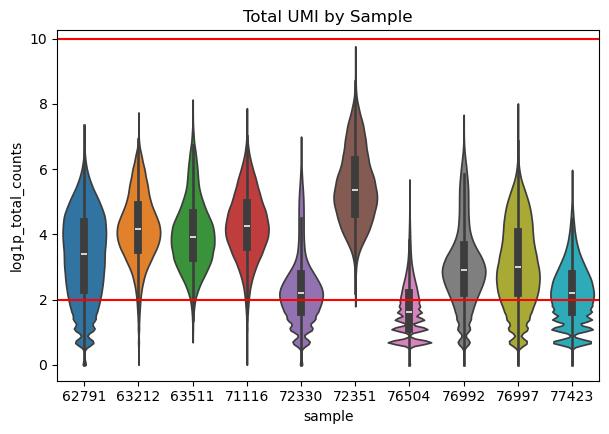

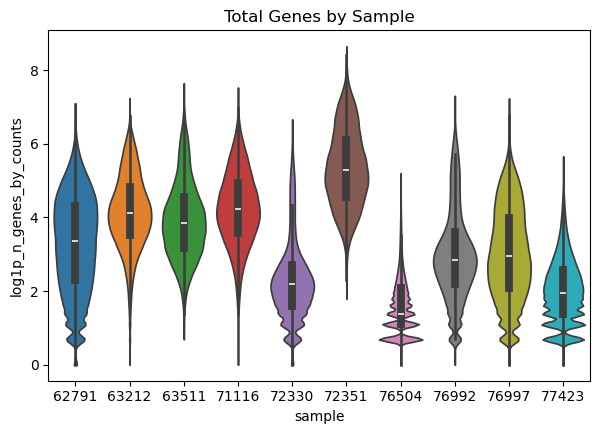

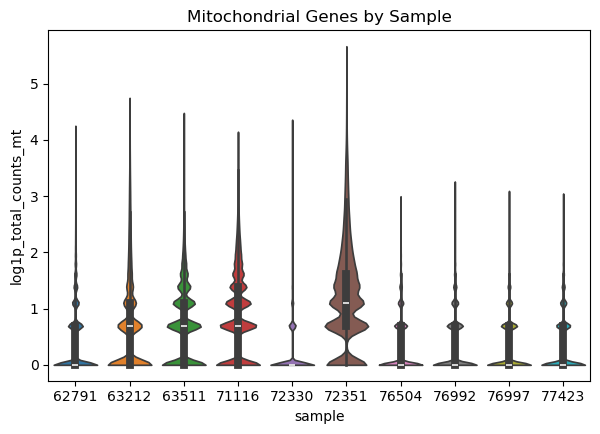

In [7]:
# Add mitochondrial gene calculation for QC
adata.var["mt"] = adata.var_names.str.startswith(("MT-", "mt-"))
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], inplace=True, percent_top=None)


# Visualization for QC
sc.pl.violin(adata=adata, keys=["log1p_total_counts"], stripplot=False, inner="box",show=False, groupby="sample",)
plt.title("Total UMI by Sample")
plt.axhline(y=2, color='r', linestyle='-')
plt.axhline(y=10, color='r', linestyle='-')
plt.title("Total UMI by Sample")
plt.show()

sc.pl.violin(adata=adata, keys=["log1p_n_genes_by_counts"], groupby="sample", stripplot=False, inner="box",show=False)
plt.title("Total Genes by Sample")
plt.show()

sc.pl.violin(adata=adata, keys=["log1p_total_counts_mt"], groupby="sample", stripplot=False, inner="box",show=False)
plt.title("Mitochondrial Genes by Sample")
plt.show()

plt.close('all')